# RQ2 procedure: from profiling traces to a validated CBS budget — audio processor

One notebook per workload, identical code; only the configuration cell changes. Run it top to bottom. Every section does one thing.

| # | Section | Output |
|---|---|---|
| 0 | Configuration and helpers | |
| 1 | Load the runs, simple statistics of C, R, W | tables and tail plot |
| 2 | Feasibility: is $N\cdot p \ge 10$? | which tolerances the empirical bound supports |
| 3 | Tail bound $C_p$ of every run | empirical upper bound with confidence |
| 4 | Factors: $\alpha_{drift}$, $\alpha_{cores}$, $\alpha_{platform}$ | inflation factors |
| 5 | Budgets: Route 1, Route 2, Route 3 | $Q^*$ per scenario, route, p; written to `budgets/` |
| 6 | Offline validation on held-out runs | pass / fail per route and p |
| 7 | Online validation under KubeDeadline | quality metrics per cell |
| 8 | Recalibration | $Q_1$ and the next budgets file |
| 9 | Replay on recorded online runs | the whole loop tested on data we already have |

**Notation.** C = CPU time of a job (`cpu_ns`), R = response time (`response_ns`), W = dispatch wait (`wait_ns`), T = period = deadline, Q = budget,
p = tolerance, the admissible probability that a job's C exceeds its budget: $P(C > Q) \le p$. $C_p$ = the $(1-p)$ quantile of C (with an upper confidence bound).

In [58]:
from pathlib import Path

# ======================== EDIT HERE (the only cell that changes between workloads) ========================
ROOT      = Path("../workload3")        # folder with results/ (profiling) and alpha_drift/ (other VMs)
WORKLOAD  = "workload3"
PERIOD_MS = 10.0                            # period = deadline T
SCENARIOS = {"single_core": ["instance0"], "multi_core": ["instance0", "instance1"]}   # scenario -> instances

CONDITIONS = ["baseline1", "cache", "memory", "baseline2"]   # profiling session (folders in ROOT/results/<scenario>/)
BASELINES, STRESS = ["baseline1", "baseline2"], ["cache", "memory"]
DRIFT_VMS = ["worker6", "worker7"]            # other VMs of the same type (ROOT/alpha_drift/results/<vm>/<scenario>/baseline|cache|memory)

P_LIST = [1e-1, 1e-2, 1e-3]                   # tolerances: admissible P(C > Q)
CONF   = 0.95                                 # confidence of every upper bound
NP_MIN = 10                                   # an empirical bound at p needs N*p >= NP_MIN, otherwise: fall back to Route 3 (HWM)
HWM_P  = 1e-3                                 # p at which Route 3 takes alpha_drift

ALPHA_PLATFORM = {1: 1.03, 2: 1.06, 3: 1.11}  # alpha_platform(m) measured once per VM type with the synthetic victims, m = enemy cores
M_USED = {"single_core": 3, "multi_core": 2}  # m used per scenario
ADMISSION_MAX = 0.95                          # budget Q/T above this is not admitted

L_BOOT, N_BOOT = 1000, 200                    # moving-block bootstrap: block length (jobs), replicates
GAP_JOBS = 50                                 # overruns closer than this (jobs) count as one cluster
K_LIST = [10, 100]                            # window lengths for the (m,k) metric
K_MAX = 2                                     # maximum number of recalibrations

INTERFERENCES = ["none", "memory"]             # online runs per budget: without interference, with the memory enemy (add "cache" if the cache runs are done)
ITER = 0                                      # 0 = first budgets; set to 1 after recalibrating, etc.
OUT_DIR = Path("budgets")                     # where the budgets of each iteration are written
BUDGETS_FILE  = OUT_DIR / f"budgets_{WORKLOAD}_iter{ITER}.csv"   # written by section 5 (the budgets to give to KubeDeadline)
ONLINE_BUDGETS = BUDGETS_FILE                 # budgets the online runs actually used (read by section 7); point it at older runs to look at them
VALID_RESULTS = ROOT / "validation_p2" / f"iter{ITER}" / "results"   # online runs: <scenario>/<route>/<ptag>_<none|memory|cache>/instance*.csv
REPLAY_RESULTS = ROOT / "validation" / "results"                         # already recorded online runs, replayed counterfactually in section 9

In [59]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import binom, beta

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40); pd.set_option("display.float_format", "{:.3f}".format)
ALPHA = 1 - CONF

def read_run(path):
    """one CSV: warm-up jobs removed, in job order"""
    df = pd.read_csv(path, usecols=["job_id", "cpu_ns", "response_ns", "wait_ns", "deadline_met", "skipped", "warmup"])
    return df[df.warmup == 0].sort_values("job_id").reset_index(drop=True)

def cp_upper(k, n):
    """Clopper-Pearson one-sided upper bound of a probability seen k times in n trials"""
    return 1.0 if k >= n else float(beta.ppf(1 - ALPHA, k + 1, n - k))

def os_ucb(xs, p):
    """order-statistic upper bound of the (1-p) quantile: x_(j), j = smallest rank with Binom(N, 1-p).cdf(j-1) >= CONF. NaN if j > N (N*p too small)"""
    n = len(xs)
    j = int(binom.ppf(CONF, n, 1 - p)) + 1
    return xs[j - 1] if j <= n else np.nan

def boot_ucb(x, ps):
    """moving-block bootstrap upper bound of the (1-p) quantile (keeps the clustering of the jobs)"""
    n = len(x); nb = n // L_BOOT
    if nb < 2:
        return np.full(len(ps), np.nan)
    rng = np.random.default_rng(0); q = np.empty((N_BOOT, len(ps)))
    for b in range(N_BOOT):
        starts = rng.integers(0, n - L_BOOT + 1, nb)
        q[b] = np.quantile(x[(starts[:, None] + np.arange(L_BOOT)).ravel()], [1 - p for p in ps])
    return np.quantile(q, CONF, axis=0)

def bound_table(x, ps):
    """C_p of a series x (ms): point estimate, the two upper bounds, and ucb = the larger one (NaN if N*p < NP_MIN)"""
    xs = np.sort(x)
    os_ = np.array([os_ucb(xs, p) for p in ps]); bt = boot_ucb(x, ps)
    ok = np.array([len(x) * p >= NP_MIN for p in ps])
    ucb = np.where(ok & ~np.isnan(os_), np.fmax(os_, bt), np.nan)
    return pd.DataFrame(dict(p=ps, point=np.quantile(x, [1 - p for p in ps]), orderstat=os_, block_boot=bt, ucb=ucb)).set_index("p")

def exceed_test(x, Q, p):
    """overruns x > Q: rate, number of clusters, upper bound of P(C>Q) = CP upper bound of clusters/N times the mean cluster size, and ucb <= p"""
    if np.isnan(Q):
        return np.nan, 0, np.nan, False
    idx = np.flatnonzero(x > Q); n = len(x)
    if len(idx) == 0:
        return 0.0, 0, cp_upper(0, n), cp_upper(0, n) <= p
    ncl = 1 + int(np.sum(np.diff(idx) > GAP_JOBS))
    ucb = cp_upper(ncl, n) * len(idx) / ncl
    return len(idx) / n, ncl, ucb, ucb <= p

def longest_run(b):
    """longest streak of True"""
    if not b.any():
        return 0
    edges = np.flatnonzero(np.diff(np.r_[0, b.astype(int), 0]))
    return int((edges[1::2] - edges[::2]).max())

def window_max(b, k):
    """worst number of True in any window of k consecutive jobs"""
    return int(np.convolve(b.astype(int), np.ones(k, int), "valid").max()) if len(b) >= k else int(b.sum())

def ptag(p):
    return "all" if p is None else "p1e-%d" % round(-math.log10(p))

## 1. Load the runs and simple statistics

Runs: the **profiling session** (`baseline1 → cache → memory → baseline2`, in `ROOT/results/`) and the runs on **other VMs** of the same type (`ROOT/alpha_drift/results/<vm>/`, the swapped session).
Skipped jobs have no C, R or W and are left out of the statistics. Warm-up jobs are always removed.

In [60]:
runs = []
for scen in SCENARIOS:
    for cond in CONDITIONS:
        runs.append(dict(run=f"profiling_{cond}", group="profiling", vm="profiling", scen=scen, cond=cond,
                         kind="base" if cond in BASELINES else "stress", dir=ROOT / "results" / scen / cond))
    for vm in DRIFT_VMS:
        for cond, kind in [("baseline", "base")] + [(c, "stress") for c in STRESS]:
            runs.append(dict(run=f"drift_{vm}_{cond}", group="drift", vm=vm, scen=scen, cond=cond, kind=kind,
                             dir=ROOT / "alpha_drift" / "results" / vm / scen / cond))
runs = [r for r in runs if (r["dir"] / "instance0.csv").exists()]

data, series = {}, {}                        # data: all jobs of a run; series: C (ms) of the non-skipped jobs, in job order
for r in runs:
    for inst in SCENARIOS[r["scen"]]:
        f = r["dir"] / f"{inst}.csv"
        if f.exists():
            key = (r["run"], r["scen"], inst)
            data[key] = read_run(f)
            d = data[key]; series[key] = (d[d.skipped == 0].cpu_ns / 1e6).to_numpy()

inv = pd.DataFrame([dict(run=k[0], scenario=k[1], instance=k[2], jobs=len(data[k]), skipped=int((data[k].skipped == 1).sum()),
                         late=int(((data[k].skipped == 0) & (data[k].deadline_met == 0)).sum())) for k in data])
display(inv.set_index(["scenario", "run", "instance"]))

jobs  skipped  late
scenario    run                    instance                        
single_core profiling_baseline1    instance0  100000        0     0
            profiling_cache        instance0  100000        3     2
            profiling_memory       instance0  100000        1     1
            profiling_baseline2    instance0  100000        4     2
            drift_worker7_baseline instance0  100000        3     1
            drift_worker7_memory   instance0  100000        6     4
multi_core  profiling_baseline1    instance0  100000        7     5
                                   instance1  100000        7     5
            profiling_cache        instance0  100000        1     1
                                   instance1  100000        1     1
            profiling_memory       instance0  100000       17    17
                                   instance1  100000       17    17
            profiling_baseline2    instance0  100000       16    13
                                   instance1  100000       16    13
            drift_worker6_baseline instance0  100000        3     1
                                   instance1  100000        3     1
            drift_worker6_memory   instance0  100000        3     2
                                   instance1  100000        3     2

### 1.1 Distribution of C, R and W in the profiling session (ms)
`cv` = std / mean. The stressed runs show how much the tail moves; baseline1 and baseline2 show the drift inside one VM.

In [61]:
def describe(v):
    q = np.quantile(v, [.5, .9, .99, .999])
    return dict(n=len(v), mean=v.mean(), cv=v.std() / v.mean(), p50=q[0], p90=q[1], p99=q[2], p999=q[3], max=v.max())

COLS = dict(C="cpu_ns", R="response_ns", W="wait_ns")
rows = []
for r in runs:
    if r["group"] != "profiling":
        continue
    for inst in SCENARIOS[r["scen"]]:
        d = data[(r["run"], r["scen"], inst)]; d = d[d.skipped == 0]
        for name, col in COLS.items():
            rows.append(dict(scenario=r["scen"], instance=inst, condition=r["cond"], quantity=name, **describe(d[col] / 1e6)))
stats = pd.DataFrame(rows)
for name in COLS:
    print(f"--- {name} ---")
    display(stats[stats.quantity == name].drop(columns="quantity").set_index(["scenario", "instance", "condition"]))

--- C ---


n  mean    cv   p50   p90   p99  p999   max
scenario    instance  condition                                                  
single_core instance0 baseline1  100000 0.966 0.038 0.964 0.989 1.047 1.203 5.950
                      cache       99997 0.973 0.049 0.970 1.002 1.064 1.219 6.684
                      memory      99999 0.959 0.033 0.958 0.984 1.035 1.153 3.917
                      baseline2   99996 0.964 0.048 0.962 1.017 1.061 1.162 5.635
multi_core  instance0 baseline1   99993 0.942 0.051 0.937 0.998 1.061 1.204 2.391
            instance1 baseline1   99993 0.956 0.050 0.952 1.008 1.079 1.229 3.151
            instance0 cache       99999 0.930 0.053 0.914 1.006 1.076 1.145 2.495
            instance1 cache       99999 0.943 0.049 0.928 1.013 1.075 1.133 2.056
            instance0 memory      99983 0.932 0.034 0.924 0.973 1.039 1.112 2.032
            instance1 memory      99983 0.951 0.032 0.944 0.991 1.052 1.124 2.074
            instance0 baseline2   99984 0.944 0.043 0.935 0.995 1.069 1.168 2.569
            instance1 baseline2   99984 0.950 0.039 0.942 0.995 1.061 1.161 2.374

--- R ---


n  mean    cv   p50   p90   p99  p999    max
scenario    instance  condition                                                   
single_core instance0 baseline1  100000 0.994 0.043 0.991 1.018 1.095 1.284  5.998
                      cache       99997 1.002 0.101 0.997 1.031 1.112 1.292 26.749
                      memory      99999 0.987 0.078 0.984 1.012 1.082 1.284 17.413
                      baseline2   99996 1.003 0.128 0.988 1.075 1.274 1.369 24.150
multi_core  instance0 baseline1   99993 0.988 0.191 0.967 1.087 1.216 1.358 38.797
            instance1 baseline1   99993 0.997 0.185 0.983 1.056 1.216 1.372 38.676
            instance0 cache       99999 0.968 0.114 0.941 1.061 1.242 1.320 12.338
            instance1 cache       99999 0.990 0.117 0.959 1.105 1.263 1.363 12.560
            instance0 memory      99983 0.963 0.151 0.953 1.004 1.073 1.161 15.702
            instance1 memory      99983 0.987 0.147 0.978 1.026 1.089 1.168 15.765
            instance0 baseline2   99984 0.978 0.198 0.967 1.029 1.106 1.220 42.763
            instance1 baseline2   99984 0.985 0.195 0.975 1.029 1.098 1.224 42.769

--- W ---


n  mean    cv   p50   p90   p99  p999    max
scenario    instance  condition                                                   
single_core instance0 baseline1  100000 0.022 0.702 0.021 0.024 0.042 0.177  2.989
                      cache       99997 0.023 3.825 0.021 0.024 0.043 0.170 25.614
                      memory      99999 0.022 3.108 0.020 0.023 0.039 0.177 16.273
                      baseline2   99996 0.033 3.389 0.020 0.038 0.234 0.324 22.759
multi_core  instance0 baseline1   99993 0.039 4.546 0.023 0.047 0.219 0.283 37.570
            instance1 baseline1   99993 0.034 5.214 0.026 0.030 0.218 0.337 37.388
            instance0 cache       99999 0.033 2.664 0.020 0.030 0.216 0.281 11.272
            instance1 cache       99999 0.041 2.280 0.026 0.048 0.228 0.342 11.406
            instance0 memory      99983 0.025 5.579 0.022 0.026 0.031 0.036 14.382
            instance1 memory      99983 0.030 4.675 0.028 0.030 0.034 0.039 14.382
            instance0 baseline2   99984 0.027 6.794 0.024 0.029 0.033 0.038 41.444
            instance1 baseline2   99984 0.028 6.572 0.027 0.030 0.033 0.038 41.484

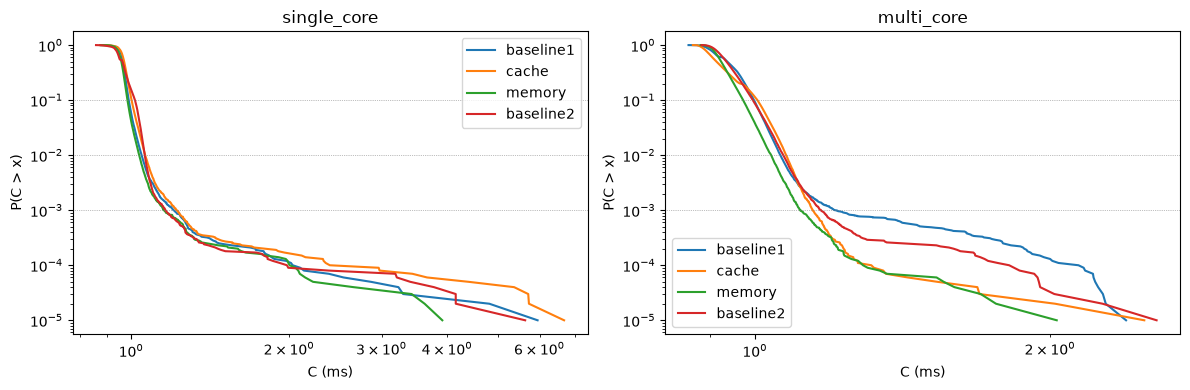

In [62]:
# survival function P(C > x) of instance0: the right end is the tail the budget has to cover
fig, axes = plt.subplots(1, len(SCENARIOS), figsize=(6 * len(SCENARIOS), 4), squeeze=False)
for ax, scen in zip(axes[0], SCENARIOS):
    for r in runs:
        key = (r["run"], scen, "instance0")
        if r["group"] == "profiling" and r["scen"] == scen:
            x = np.sort(series[key]); ax.loglog(x, 1 - np.arange(1, len(x) + 1) / len(x) + 1 / len(x), label=r["cond"])
    for p in P_LIST:
        ax.axhline(p, color="grey", lw=.5, ls=":")
    ax.set_title(scen); ax.set_xlabel("C (ms)"); ax.set_ylabel("P(C > x)"); ax.legend()
plt.tight_layout(); plt.show()

## 2. Feasibility: is $N\cdot p \ge 10$?

The empirical bound of the $(1-p)$ quantile needs enough jobs above it. With N jobs the expected number of jobs beyond the quantile is $N\cdot p$; we ask for $N\cdot p \ge 10$ (the order-statistic bound at 95% needs $N \gtrsim 3/p$ at the very least).
For a tolerance that does not meet it, the empirical Routes 1 and 2 are **not available** and the budget falls back to **Route 3 (high-water mark)**, or more data has to be collected.
EVT is not part of the procedure: a practitioner who wants it has to check its fit separately.

In [63]:
rows = [dict(scenario=k[1], run=k[0], instance=k[2], N=len(series[k]), **{f"N*p (p={p:g})": len(series[k]) * p for p in P_LIST}) for k in series]
feas = pd.DataFrame(rows)
display(feas.set_index(["scenario", "run", "instance"]))

feasible = {(scen, p): all(len(series[k]) * p >= NP_MIN for k in series if k[1] == scen) for scen in SCENARIOS for p in P_LIST}
print(pd.Series(feasible).unstack().rename_axis(index="scenario", columns="p").to_string())
print("\nFalse = N*p < %d in at least one run: Routes 1 and 2 fall back to Route 3 for that p." % NP_MIN)

N  N*p (p=0.1)  N*p (p=0.01)  N*p (p=0.001)
scenario    run                    instance                                                   
single_core profiling_baseline1    instance0  100000    10000.000      1000.000        100.000
            profiling_cache        instance0   99997     9999.700       999.970         99.997
            profiling_memory       instance0   99999     9999.900       999.990         99.999
            profiling_baseline2    instance0   99996     9999.600       999.960         99.996
            drift_worker7_baseline instance0   99997     9999.700       999.970         99.997
            drift_worker7_memory   instance0   99994     9999.400       999.940         99.994
multi_core  profiling_baseline1    instance0   99993     9999.300       999.930         99.993
                                   instance1   99993     9999.300       999.930         99.993
            profiling_cache        instance0   99999     9999.900       999.990         99.999
                                   instance1   99999     9999.900       999.990         99.999
            profiling_memory       instance0   99983     9998.300       999.830         99.983
                                   instance1   99983     9998.300       999.830         99.983
            profiling_baseline2    instance0   99984     9998.400       999.840         99.984
                                   instance1   99984     9998.400       999.840         99.984
            drift_worker6_baseline instance0   99997     9999.700       999.970         99.997
                                   instance1   99997     9999.700       999.970         99.997
            drift_worker6_memory   instance0   99997     9999.700       999.970         99.997
                                   instance1   99997     9999.700       999.970         99.997

p            0.001  0.010  0.100
scenario                        
multi_core    True   True   True
single_core   True   True   True

False = N*p < 10 in at least one run: Routes 1 and 2 fall back to Route 3 for that p.


## 3. Tail bound $C_p$ of every run

For a run with N job times $x_1,\dots,x_N$ and tolerance p, $C_p$ is the $(1-p)$ quantile, bounded from above with confidence `CONF`:

- **order statistic:** the number of jobs below the true quantile follows $\mathrm{Binomial}(N, 1-p)$, so the sorted sample element $x_{(j)}$ with $j=\min\{j: F_{Bin}(j-1)\ge CONF\}$ is an upper bound. Valid for independent jobs.
- **moving-block bootstrap:** resample blocks of `L_BOOT` consecutive jobs and take the `CONF` quantile of the bootstrap quantiles. Keeps the clustering of slow jobs.
- **$C_p$ = the larger of the two** (`ucb`). NaN when $N\cdot p < $ `NP_MIN`.

The next cells use `ucb` only.

In [64]:
bnd = {k: bound_table(series[k], P_LIST) for k in series}
rows = [dict(scenario=k[1], instance=k[2], run=k[0], p=p, **bnd[k].loc[p].to_dict()) for k in bnd for p in P_LIST]
bt = pd.DataFrame(rows)
display(bt.pivot_table(index=["scenario", "instance", "run"], columns="p", values="ucb", sort=False))

p                                             0.100  0.010  0.001
scenario    instance  run                                        
single_core instance0 profiling_baseline1     0.991  1.051  1.237
                      profiling_cache         1.004  1.069  1.239
                      profiling_memory        0.986  1.039  1.182
                      profiling_baseline2     1.018  1.063  1.181
                      drift_worker7_baseline  1.004  1.074  1.136
                      drift_worker7_memory    0.983  1.051  1.280
multi_core  instance0 profiling_baseline1     1.000  1.069  1.652
                      profiling_cache         1.009  1.080  1.155
                      profiling_memory        0.976  1.045  1.129
                      profiling_baseline2     0.998  1.074  1.197
                      drift_worker6_baseline  1.147  1.314  1.459
                      drift_worker6_memory    1.039  1.202  1.375
            instance1 profiling_baseline1     1.012  1.089  1.671
                      profiling_cache         1.016  1.079  1.140
                      profiling_memory        0.993  1.058  1.134
                      profiling_baseline2     0.998  1.066  1.210
                      drift_worker6_baseline  1.158  1.327  1.440
                      drift_worker6_memory    1.034  1.191  1.347

## 4. Factors

### 4.1 $\alpha_{drift}$: variation of the bound between runs and VMs
Every baseline run of a scenario (the two profiling baselines and the baselines on the other VMs) gets its own $C_p$. With $C_p(r)$ the bound of run r:

$$\alpha_{drift}(p) = \frac{\max_r C_p(r)}{\min_r C_p(r)}$$

per instance; the deployment value is the worst instance. With n runs, a new run is covered with probability about $n/(n+1)$ (exchangeable runs), so n is reported: **few runs mean a weak guarantee**.
An episode inside one baseline is not removed: it enters the spread, which is what the factor is for.

In [65]:
rows = []
for scen, insts in SCENARIOS.items():
    names = [r["run"] for r in runs if r["scen"] == scen and r["kind"] == "base"]
    for inst in insts:
        for p in P_LIST:
            v = np.array([bnd[(n, scen, inst)].loc[p, "ucb"] for n in names if (n, scen, inst) in bnd])
            rows.append(dict(scenario=scen, instance=inst, p=p, n_runs=len(v), alpha=v.max() / v.min()))
spread = pd.DataFrame(rows)
alpha_drift = spread.groupby(["scenario", "p"]).agg(alpha=("alpha", "max"), n_runs=("n_runs", "min"))
alpha_drift["coverage n/(n+1)"] = alpha_drift.n_runs / (alpha_drift.n_runs + 1)
display(alpha_drift)

alpha  n_runs  coverage n/(n+1)
scenario    p                                     
multi_core  0.001  1.381       3             0.750
            0.010  1.245       3             0.750
            0.100  1.161       3             0.750
single_core 0.001  1.089       3             0.750
            0.010  1.022       3             0.750
            0.100  1.027       3             0.750

### 4.2 $\alpha_{cores}$ (stress) and $\alpha_{platform}$
- $\alpha_{cores}(p) = C_p^{stress} / C_p^{base}$ measured on the profiling VM, one value per stressor. It tells how much the stress moves the tail (reported; Route 1 already contains it).
- $\alpha_{platform}(m)$ is the factor of the synthetic victims (measured once per VM type, `ALPHA_PLATFORM`, m = number of enemy cores). Route 2 uses it in place of the stress profiling of the task.

In [66]:
def prof_runs(scen, kind):
    return [r["run"] for r in runs if r["scen"] == scen and r["group"] == "profiling" and r["kind"] == kind]

rows = []
for scen, insts in SCENARIOS.items():
    for inst in insts:
        for p in P_LIST:
            base = np.max([bnd[(n, scen, inst)].loc[p, "ucb"] for n in prof_runs(scen, "base")])
            for n in prof_runs(scen, "stress"):
                rows.append(dict(scenario=scen, instance=inst, p=p, stress=n.replace("profiling_", ""), alpha_cores=bnd[(n, scen, inst)].loc[p, "ucb"] / base))
ac = pd.DataFrame(rows)
display(ac.groupby(["scenario", "stress", "p"]).alpha_cores.max().unstack("p"))
print("alpha_platform used:", {s: (M_USED[s], ALPHA_PLATFORM[M_USED[s]]) for s in SCENARIOS}, "(scenario: (m, factor))")

p                   0.001  0.010  0.100
scenario    stress                     
multi_core  cache   0.699  1.005  1.009
            memory  0.683  0.973  0.982
single_core cache   1.002  1.005  0.987
            memory  0.956  0.978  0.969

alpha_platform used: {'single_core': (3, 1.11), 'multi_core': (2, 1.06)} (scenario: (m, factor))


## 5. Budgets

$C_p^{base}$ = largest bound of the two profiling baselines, $C_p^{stress}$ = largest bound over the stressed runs (cache, memory), per instance. One reservation serves all instances of a scenario, so the deployment budget $Q^*$ is the **maximum over the instances**.

| Route | Formula | Needs |
|---|---|---|
| 1 (full profiling) | $Q = C_p^{stress}\cdot\alpha_{drift}(p)$ | stress profiling of the task |
| 2 (baseline + platform factor) | $Q = C_p^{base}\cdot\alpha_{platform}(m)\cdot\alpha_{drift}(p)$ | baseline profiling only |
| 3 (high-water mark) | $Q = \max C^{stress}\cdot\alpha_{drift}(HWM_P)$, **one value for every p** | stress profiling; no tail estimate. Jobs with $C>2T$ (stalls) are left out of the maximum |

Rules applied after the formulas: (i) where $N\cdot p<10$ Route 1 and 2 are replaced by Route 3 (marked `*`); (ii) **monotone in p**: a stricter tolerance never gets a smaller budget than a looser one; (iii) admission: $Q/T \le$ `ADMISSION_MAX` for Routes 1 and 2, while **Route 3 is capped at `ADMISSION_MAX` $\cdot T$** (a high-water mark above that is useless): the cap is flagged `(capped)` and the share of stressed jobs left above it is printed.

In [67]:
def hwm_ms(scen, inst):
    return max(series[(n, scen, inst)][series[(n, scen, inst)] <= 2 * PERIOD_MS].max() for n in prof_runs(scen, "stress"))

def finalize(raw):
    """raw: scenario, route, p, Q_raw (ms) -> fallback to Route 3 where NaN, monotone envelope in p, Q/T, admission"""
    out = []
    for (scen, route), g in raw.groupby(["scenario", "route"], sort=False):
        g = g.sort_values("p", ascending=False).copy()                    # loosest tolerance first
        h = raw[(raw.scenario == scen) & (raw.route == "hwm")].Q_raw.iloc[0]
        g["fallback"] = g.Q_raw.isna() & (route != "hwm")
        g["Q_ms"] = g.Q_raw.fillna(h).cummax()                           # a stricter p is never cheaper
        out.append(g)
    out = pd.concat(out)
    out["Q_over_T"] = out.Q_ms / PERIOD_MS
    out["admitted"] = out.Q_over_T <= ADMISSION_MAX
    return out.reset_index(drop=True)

rows = []
for scen, insts in SCENARIOS.items():
    a_h = alpha_drift.loc[(scen, HWM_P), "alpha"]; a_h = 1.0 if np.isnan(a_h) else a_h
    q3_raw = max(hwm_ms(scen, i) for i in insts) * a_h
    q3 = min(q3_raw, ADMISSION_MAX * PERIOD_MS)                  # Route 3 is only useful if admissible: cap it at the largest admissible budget
    for p in P_LIST:
        a = alpha_drift.loc[(scen, p), "alpha"]
        q1, q2 = [], []
        for inst in insts:
            base = np.max([bnd[(n, scen, inst)].loc[p, "ucb"] for n in prof_runs(scen, "base")])
            stress = np.max([bnd[(n, scen, inst)].loc[p, "ucb"] for n in prof_runs(scen, "stress")])
            q1.append(stress * a); q2.append(base * ALPHA_PLATFORM[M_USED[scen]] * a)
        rows += [dict(scenario=scen, route="route1", p=p, Q_raw=np.max(q1)), dict(scenario=scen, route="route2b", p=p, Q_raw=np.max(q2)),
                 dict(scenario=scen, route="hwm", p=p, Q_raw=q3, hwm_capped=bool(q3_raw > q3))]
raw = pd.DataFrame(rows)
raw["hwm_capped"] = raw.hwm_capped.fillna(False).astype(bool)
bud = finalize(raw)

show = bud.assign(cell=lambda x: x.Q_ms.round(3).astype(str) + " (" + x.Q_over_T.round(3).astype(str) + ")" + np.where(x.fallback, "*", "") + np.where(x.hwm_capped, " (capped)", "") + np.where(x.admitted, "", " NOT ADMITTED"))
display(show.pivot_table(index=["scenario", "route"], columns="p", values="cell", aggfunc="first"))
print("cell = Q* in ms (Q*/T);  * = fallback to Route 3 because N*p < %d;  (capped) = Route 3 cut at ADMISSION_MAX * T" % NP_MIN)
for scen in SCENARIOS:                                                            # a capped Route 3 is not a high-water mark any more: show what it leaves uncovered
    g = bud[(bud.scenario == scen) & (bud.route == "hwm") & bud.hwm_capped]
    if len(g):
        c = np.concatenate([series[(n, scen, i)] for n in prof_runs(scen, "stress") for i in SCENARIOS[scen]])
        print(f"{scen}: Route 3 capped at {g.Q_ms.iloc[0]:.2f} ms; {np.mean(c > g.Q_ms.iloc[0]):.2e} of the stressed-run jobs are still above it")

p                            0.001          0.010          0.100
scenario    route                                               
multi_core  hwm      3.446 (0.345)  3.446 (0.345)  3.446 (0.345)
            route1   1.594 (0.159)  1.345 (0.135)  1.179 (0.118)
            route2b  2.446 (0.245)  1.437 (0.144)  1.245 (0.125)
single_core hwm      7.276 (0.728)  7.276 (0.728)  7.276 (0.728)
            route1   1.349 (0.135)  1.092 (0.109)  1.031 (0.103)
            route2b  1.495 (0.149)  1.206 (0.121)   1.16 (0.116)

cell = Q* in ms (Q*/T);  * = fallback to Route 3 because N*p < 10;  (capped) = Route 3 cut at ADMISSION_MAX * T


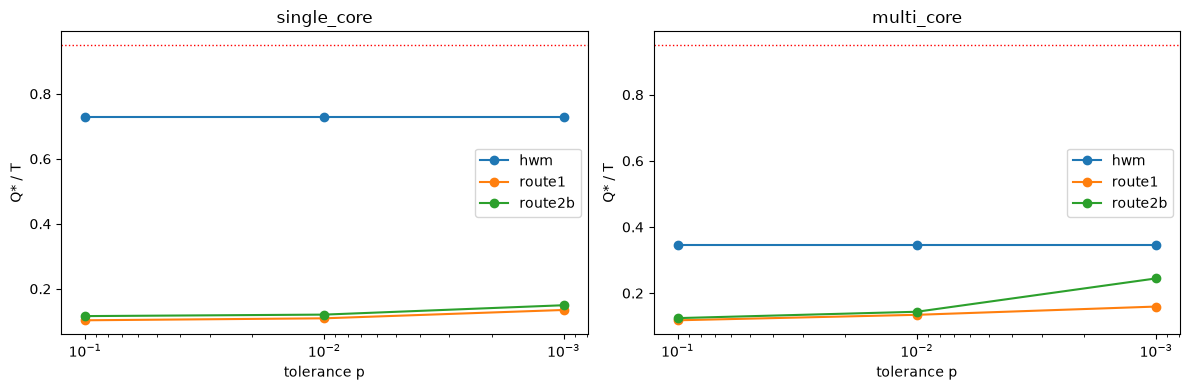

written budgets/budgets_workload3_iter0.csv


In [68]:
fig, axes = plt.subplots(1, len(SCENARIOS), figsize=(6 * len(SCENARIOS), 4), squeeze=False)
for ax, scen in zip(axes[0], SCENARIOS):
    for route, g in bud[bud.scenario == scen].groupby("route"):
        ax.plot(g.p, g.Q_over_T, "o-", label=route)
    ax.axhline(ADMISSION_MAX, color="red", ls=":", lw=1); ax.set_xscale("log"); ax.invert_xaxis()
    ax.set_title(scen); ax.set_xlabel("tolerance p"); ax.set_ylabel("Q* / T"); ax.legend()
plt.tight_layout(); plt.show()

# file for the validation driver: same format as validation/budgets.csv (Route 3 is one row, p = "all")
def export_budgets(table, path):
    OUT_DIR.mkdir(exist_ok=True)
    exp = table[(table.route != "hwm") | (table.p == HWM_P)].copy()
    exp["p"] = [("all" if r == "hwm" else p) for r, p in zip(exp.route, exp.p)]
    exp["runtime_us"] = (exp.Q_ms * 1000).round().astype(int); exp["period_us"] = round(PERIOD_MS * 1000)
    exp[["scenario", "route", "p", "Q_ms", "Q_over_T", "runtime_us", "period_us", "admitted"]].to_csv(path, index=False)

export_budgets(bud, BUDGETS_FILE)
print("written", BUDGETS_FILE)

## 6. Offline validation on held-out data

A budget is **valid on a held-out run** if its overrun probability $P(C>Q)$ is at most p, judged with the upper confidence bound of `exceed_test`:
overruns closer than `GAP_JOBS` jobs form one cluster, $P_{ucb} = CP_{upper}(\#clusters, N)\cdot(\text{mean cluster size})$, pass if $P_{ucb}\le p$.

- **6.1 Held-out baselines (leave one run out).** For each baseline run h except the reference (`baseline1`): $\alpha_{drift}$ from the **other** runs, $Q = C_p(\text{reference})\cdot\alpha_{drift}^{(-h)}$, applied to h. Tests whether the spread rule predicts a new run.
- **6.2 Held-out stressed runs.** The stressed runs on the other VMs are not used by any factor. The budgets of section 5 (Route 1 and 2) are applied to them.

In [69]:
ref = "profiling_baseline1"
rows = []
for scen, insts in SCENARIOS.items():
    names = [r["run"] for r in runs if r["scen"] == scen and r["kind"] == "base"]
    for h in names:
        if h == ref:
            continue
        for inst in insts:
            for p in P_LIST:
                c_ref = bnd[(ref, scen, inst)].loc[p, "ucb"]
                v = np.array([bnd[(n, scen, inst)].loc[p, "ucb"] for n in names if n != h])
                Q = c_ref * v.max() / v.min()                                   # before: spread of the OTHER runs
                rate, ncl, ucb, ok = exceed_test(series[(h, scen, inst)], Q, p)
                Q1 = max(Q, c_ref * alpha_drift.loc[(scen, p), "alpha"])        # after: alpha_drift of 4.1 (all runs, h included)
                rate1, ncl1, ucb1, ok1 = exceed_test(series[(h, scen, inst)], Q1, p)
                rows.append(dict(scenario=scen, held_out=h, instance=inst, p=p, Q_ms=Q, overrun_rate=rate, clusters=ncl, P_ucb=ucb, passed=ok,
                                 Q1_ms=Q1, overrun_rate1=rate1, clusters1=ncl1, P_ucb1=ucb1, passed1=ok1))
loo = pd.DataFrame(rows)
display(loo.set_index(["scenario", "held_out", "instance", "p"]))
print(loo.groupby(["scenario", "p"]).agg(tests=("passed", "size"), passed_before=("passed", "sum"), passed_after=("passed1", "sum")).to_string())
print("\n'after' uses alpha_drift WITH the held-out run: a consistency check, not an independent validation (see 6.3).")

Q_ms  overrun_rate  clusters  P_ucb  passed  Q1_ms  overrun_rate1  clusters1  P_ucb1  passed1
scenario    held_out               instance  p                                                                                                   
single_core profiling_baseline2    instance0 0.100 1.004         0.141        60  0.174   False  1.018          0.098        105   0.115    False
                                             0.010 1.074         0.005       321  0.006    True  1.074          0.005        321   0.006     True
                                             0.001 1.347         0.000        22  0.000    True  1.347          0.000         22   0.000     True
            drift_worker7_baseline instance0 0.100 1.018         0.057       385  0.062    True  1.018          0.057        385   0.062     True
                                             0.010 1.063         0.012       349  0.014   False  1.074          0.008        323   0.009     True
                                             0.001 1.296         0.000         8  0.000    True  1.347          0.000          7   0.000     True
multi_core  profiling_baseline2    instance0 0.100 1.147         0.001        80  0.002    True  1.162          0.001         63   0.001     True
                                             0.010 1.314         0.000         9  0.000    True  1.331          0.000          9   0.000     True
                                             0.001 1.872         0.000         3  0.000    True  2.282          0.000          1   0.000     True
                                   instance1 0.100 1.158         0.001        65  0.001    True  1.175          0.001         58   0.001     True
                                             0.010 1.327         0.000        11  0.001    True  1.356          0.000          8   0.000     True
                                             0.001 1.939         0.000         2  0.000    True  2.307          0.000          1   0.000     True
            drift_worker6_baseline instance0 0.100 1.003         0.522       119  0.607   False  1.162          0.061        252   0.068     True
                                             0.010 1.074         0.241       260  0.267   False  1.331          0.005        118   0.006     True
                                             0.001 2.282         0.000        10  0.000    True  2.282          0.000         10   0.000     True
                                   instance1 0.100 1.026         0.438       242  0.487   False  1.175          0.060        199   0.067     True
                                             0.010 1.112         0.152       174  0.173   False  1.356          0.004         80   0.005     True
                                             0.001 2.307         0.000         0  0.000    True  2.307          0.000          0   0.000     True

                   tests  passed_before  passed_after
scenario    p                                        
multi_core  0.001      4              4             4
            0.010      4              2             4
            0.100      4              2             4
single_core 0.001      2              2             2
            0.010      2              1             2
            0.100      2              1             1

'after' uses alpha_drift WITH the held-out run: a consistency check, not an independent validation (see 6.3).


In [70]:
rows = []
for r in runs:
    if not (r["group"] == "drift" and r["kind"] == "stress"):
        continue
    for inst in SCENARIOS[r["scen"]]:
        key = (r["run"], r["scen"], inst)
        if key not in series:
            continue
        for route in ("route1", "route2b"):
            for p in P_LIST:
                Q = bud[(bud.scenario == r["scen"]) & (bud.route == route) & (bud.p == p)].Q_ms.iloc[0]
                rate, ncl, ucb, ok = exceed_test(series[key], Q, p)
                rows.append(dict(scenario=r["scen"], held_out=r["run"], instance=inst, route=route, p=p, Q_ms=Q, overrun_rate=rate, clusters=ncl, P_ucb=ucb, passed=ok))
held = pd.DataFrame(rows)
if len(held):
    display(held.set_index(["scenario", "held_out", "instance", "route", "p"]))
    print(held.groupby(["scenario", "route", "p"]).passed.all().unstack("p").to_string())
else:
    print("no stressed runs on the other VMs")

Q_ms  overrun_rate  clusters  P_ucb  passed
scenario    held_out             instance  route   p                                                 
single_core drift_worker7_memory instance0 route1  0.100 1.031         0.015       340  0.017    True
                                                   0.010 1.092         0.003       104  0.003    True
                                                   0.001 1.349         0.001        17  0.001    True
                                           route2b 0.100 1.160         0.001        49  0.001    True
                                                   0.010 1.206         0.001        38  0.001    True
                                                   0.001 1.495         0.000        14  0.001    True
multi_core  drift_worker6_memory instance0 route1  0.100 1.179         0.008       134  0.009    True
                                                   0.010 1.345         0.001        45  0.001    True
                                                   0.001 1.594         0.000        14  0.000    True
                                           route2b 0.100 1.245         0.004        87  0.004    True
                                                   0.010 1.437         0.000        25  0.000    True
                                                   0.001 2.446         0.000         3  0.000    True
                                 instance1 route1  0.100 1.179         0.006        77  0.008    True
                                                   0.010 1.345         0.001        27  0.001    True
                                                   0.001 1.594         0.000         7  0.000    True
                                           route2b 0.100 1.245         0.003        63  0.004    True
                                                   0.010 1.437         0.000        13  0.000    True
                                                   0.001 2.446         0.000         1  0.000    True

p                    0.001  0.010  0.100
scenario    route                       
multi_core  route1    True   True   True
            route2b   True   True   True
single_core route1    True   True   True
            route2b   True   True   True


### 6.3 Offline recalibration of the failed baseline tests
Every (held-out run, instance, p) that failed in 6.1 becomes a drift sample:

- $\alpha_{before}$ = the spread **without** that run (the factor that failed in 6.1),
- $\alpha_{after}$ = the spread **with every run** (the value of section 4.1, used by the budgets of section 5),
- $Q_0 = C_p^{ref}\cdot\alpha_{before}$ and $Q_1 = \max(Q_0,\ C_p^{ref}\cdot\alpha_{after})$.

$Q_1$ is already re-tested on the held-out run in the table of 6.1 (`*1` columns), but that run is now part of the calibration, so this is **not** an independent validation: it only shows that the recalibrated value is consistent with the data it contains. The independent offline check of the recalibrated budgets is 6.2 (stressed runs of the other VMs), and the final one is the online run.

In [71]:
fail = loo[~loo.passed]
recal_offline = fail.assign(alpha_before=lambda x: x.Q_ms / [bnd[(ref, r.scenario, r.instance)].loc[r.p, "ucb"] for r in x.itertuples()],
                            alpha_after=lambda x: [alpha_drift.loc[(r.scenario, r.p), "alpha"] for r in x.itertuples()],
                            Q1_over_Q0=lambda x: x.Q1_ms / x.Q_ms)
cols = ["alpha_before", "alpha_after", "Q_ms", "Q1_ms", "Q1_over_Q0", "P_ucb", "P_ucb1", "passed1"]
if len(recal_offline):
    display(recal_offline.set_index(["scenario", "held_out", "instance", "p"])[cols].rename(columns={"Q_ms": "Q0", "Q1_ms": "Q1", "passed1": "passes_after"}))
else:
    print("every held-out baseline test passed: no recalibration needed")

alpha_before  alpha_after    Q0    Q1  Q1_over_Q0  P_ucb  P_ucb1  passes_after
scenario    held_out               instance  p                                                                                    
single_core profiling_baseline2    instance0 0.100         1.013        1.027 1.004 1.018       1.014  0.174   0.115         False
            drift_worker7_baseline instance0 0.010         1.012        1.022 1.063 1.074       1.010  0.014   0.009          True
multi_core  drift_worker6_baseline instance0 0.100         1.002        1.161 1.003 1.162       1.159  0.607   0.068          True
                                             0.010         1.005        1.245 1.074 1.331       1.239  0.267   0.006          True
                                   instance1 0.100         1.014        1.161 1.026 1.175       1.145  0.487   0.067          True
                                             0.010         1.022        1.245 1.112 1.356       1.219  0.173   0.005          True

### If a held-out test fails
An offline failure means the held-out data contain variation the profiling did not. Before changing anything:

1. **Setup:** was the run made under the same conditions (VM type, threads, input, enemy placement)? If not it is not a valid test: exclude it and say why.
2. **Episode:** is the failure confined to a stretch of the run (a stall or burst)? With an *episode-excluded* policy it is reported as an episode with its rate; with *episode-inclusive* it is a failure.
3. **Drift larger than $\alpha_{drift}$** (the usual cause when the distribution is narrow, e.g. the audio workload): $\alpha_{drift}$ came from few runs and the held-out run is a new sample outside the observed spread.

Then recalibrate **once**: the held-out run becomes one more drift sample. Section 4 already uses every baseline run, so the budgets of section 5 are the recalibrated ones; rerun from section 4 after adding the run to `alpha_drift/results/`. Do not iterate offline repeatedly: each round uses up a held-out set. After that the **online run is the independent test**.

### 6.4 Budgets to test online

The table collects, for every budget of section 5, the offline verdicts and a status. It is the list of what to run online.

- `baseline_heldout`: the drift rule on held-out baselines after recalibration (6.1, `passed1`), for the scenario and p. It does not depend on the route. In-sample for the runs that set $\alpha_{drift}$.
- `stress_heldout`: the budget on the stressed runs of the other VMs (6.2), independent of every factor. Empty if there are none, or for Route 3.
- Status: *ready* if admitted and no offline test failed; otherwise the reason. A failed offline test does not remove the cell: it is still run online, because the online run is the final test, but it is marked so the result is not a surprise.

Two files are written in `OUT_DIR`: `BUDGETS_FILE` (driver format, unchanged columns) and the same name with `_offline` (with the verdicts).

In [72]:
base_ok = loo.groupby(["scenario", "p"]).passed1.all()
stress_ok = held.groupby(["scenario", "route", "p"]).passed.all() if len(held) else pd.Series(dtype=bool)

final = bud.copy()
final["baseline_heldout"] = [np.nan if r.route == "hwm" else base_ok.get((r.scenario, r.p), np.nan) for r in final.itertuples()]
final["stress_heldout"] = [stress_ok.get((r.scenario, r.route, r.p), np.nan) for r in final.itertuples()]

def status(r):
    if not r.admitted:
        return "NOT ADMITTED (Q/T above the limit)"
    if r.fallback:
        return "Route 3 value (N*p too small for the empirical bound)"
    if r.hwm_capped:
        return "Route 3 capped at ADMISSION_MAX*T: not a high-water mark any more"
    if pd.notna(r.stress_heldout) and not r.stress_heldout:
        return "run online: offline stress test FAILED"
    if pd.notna(r.baseline_heldout) and not r.baseline_heldout:
        return "run online: offline drift test FAILED"
    return "ready"
final["status"] = [status(r) for r in final.itertuples()]

to_show = final[(final.route != "hwm") | (final.p == HWM_P)]                   # Route 3 is one budget for every p
display(to_show[["scenario", "route", "p", "Q_ms", "Q_over_T", "admitted", "baseline_heldout", "stress_heldout", "status"]].reset_index(drop=True))

OUT_DIR.mkdir(exist_ok=True)
export_budgets(final, BUDGETS_FILE)                                              # driver file (same Q as section 5)
off = to_show.copy(); off["p"] = [("all" if r == "hwm" else p) for r, p in zip(off.route, off.p)]
off_file = BUDGETS_FILE.with_name(BUDGETS_FILE.stem + "_offline.csv")
off[["scenario", "route", "p", "Q_ms", "Q_over_T", "admitted", "baseline_heldout", "stress_heldout", "status"]].to_csv(off_file, index=False)
n_cells = int(to_show.admitted.sum())
print(f"written {BUDGETS_FILE} and {off_file}")
print(f"online runs to do: {n_cells} admitted budgets x {len(INTERFERENCES)} ({' / '.join(INTERFERENCES)}) = {len(INTERFERENCES) * n_cells}, each over {', '.join(f'{len(v)} instance(s) ({k})' for k, v in SCENARIOS.items())}")

,scenario,route,p,Q_ms,Q_over_T,admitted,baseline_heldout,stress_heldout,status
0,single_core,route1,0.100,1.031,0.103,True,False,True,run online: offline drift test FAILED
1,single_core,route1,0.010,1.092,0.109,True,True,True,ready
2,single_core,route1,0.001,1.349,0.135,True,True,True,ready
3,single_core,route2b,0.100,1.160,0.116,True,False,True,run online: offline drift test FAILED
4,single_core,route2b,0.010,1.206,0.121,True,True,True,ready
5,single_core,route2b,0.001,1.495,0.149,True,True,True,ready
6,single_core,hwm,0.001,7.276,0.728,True,NaN,NaN,ready
7,multi_core,route1,0.100,1.179,0.118,True,True,True,ready
8,multi_core,route1,0.010,1.345,0.135,True,True,True,ready
9,multi_core,route1,0.001,1.594,0.159,True,True,True,ready


written budgets/budgets_workload3_iter0.csv and budgets/budgets_workload3_iter0_offline.csv
online runs to do: 14 admitted budgets x 2 (none / memory) = 28, each over 1 instance(s) (single_core), 2 instance(s) (multi_core)


## 7. Online validation under KubeDeadline

The budgets of `BUDGETS_FILE` (section 5) are given to KubeDeadline and the workload runs under them (without interference, with the memory enemy and with the cache enemy). Results are read from `VALID_RESULTS/<scenario>/<route>/<ptag>_<none|memory|cache>/instance*.csv`.
If the folder does not exist yet this section prints a message and the next one is skipped. To look at older runs, point `VALID_RESULTS` and `ONLINE_BUDGETS` at them in the configuration cell.

Per run (and instance) the quality metrics are:

| Metric | Meaning |
|---|---|
| `P_over`, `P_ucb`, `passed` | observed $P(C>Q)$ (jobs with $C>Q$ / non-skipped jobs), its cluster-aware upper bound, and $P_{ucb}\le p$ |
| `obs/p` | share of the allowed overruns that was used |
| `over_budget` | $Q / \hat C_p^{val} - 1$ with $\hat C_p^{val}$ the $(1-p)$ quantile seen in this run (the budget that would have been just enough); negative = budget too small |
| `miss_rate` | $P(R>T)$ = (late + skipped) / jobs, split into `late_over` (C>Q), `late_other` (C≤Q: stalls, scheduler) and `skipped` |
| `longest`, `m@k` | longest streak of consecutive missed jobs, and the worst number of misses in any window of k jobs |

For Route 3 (one budget for every p) the run is judged at `HWM_P`.

In [73]:
def online_row(df, Q, p):
    ok = df[df.skipped == 0]
    c = (ok.cpu_ns / 1e6).to_numpy(); late = (ok.deadline_met == 0).to_numpy()
    rate, ncl, ucb, passed = exceed_test(c, Q, p)
    bad = ((df.skipped == 1) | (df.deadline_met == 0)).to_numpy()
    row = dict(N=len(c), P_over=rate, P_ucb=ucb, passed=passed, obs_over_p=rate / p, over_budget=Q / np.quantile(c, 1 - p) - 1,
               miss_rate=bad.mean(), late_over=int((late & (c > Q)).sum()), late_other=int((late & (c <= Q)).sum()), skipped=int((df.skipped == 1).sum()),
               longest=longest_run(bad))
    row.update({f"m@{k}": window_max(bad, k) for k in K_LIST})
    return row, c

online, val_c = [], {}
if ONLINE_BUDGETS.exists() and VALID_RESULTS.exists():
    for _, b in pd.read_csv(ONLINE_BUDGETS, dtype={"p": str}).iterrows():
        is_hwm = b.route == "hwm"
        p = HWM_P if is_hwm else float(b.p)
        for interf in INTERFERENCES:
            d = VALID_RESULTS / b.scenario / b.route / f"{'all' if is_hwm else ptag(p)}_{interf}"
            for inst in SCENARIOS[b.scenario]:
                if (d / f"{inst}.csv").exists():
                    row, c = online_row(read_run(d / f"{inst}.csv"), b.runtime_us / 1000, p)
                    online.append(dict(scenario=b.scenario, route=b.route, p=p, interference=interf, instance=inst, Q_ms=b.runtime_us / 1000, **row))
                    val_c[(b.scenario, b.route, p, interf, inst)] = c
online = pd.DataFrame(online)
if len(online):
    display(online.set_index(["scenario", "route", "p", "interference", "instance"]))
    print("passed in every instance:")
    print(online.groupby(["scenario", "route", "p", "interference"]).passed.all().unstack("interference").to_string())
else:
    print(f"no online results yet in {VALID_RESULTS} (budgets: {ONLINE_BUDGETS})")

Q_ms      N  P_over  P_ucb  passed  obs_over_p  over_budget  miss_rate  late_over  late_other  skipped  longest  m@10  m@100
scenario    route   p     interference instance                                                                                                                               
single_core route1  0.100 none         instance0 1.031  45633   0.087  0.102   False       0.872        0.031      0.175       3977         383     4367      855    10    100
                          memory       instance0 1.031  42161   0.070  0.079    True       0.704        0.015      0.313       2968        4851     7839      124    10    100
                    0.010 none         instance0 1.092  49878   0.002  0.002    True       0.162        0.146      0.005         81          39      122       76    10     76
                          memory       instance0 1.092  49451   0.008  0.011   False       0.777        0.040      0.022        384         165      549      128    10    100
                    0.001 none         instance0 1.349  49999   0.000  0.000    True       0.020        0.369      0.000          1           0        1        2     2      2
                          memory       instance0 1.349  49989   0.000  0.000    True       0.140        0.216      0.000          7           2       11        4     4      4
            route2b 0.100 none         instance0 1.160  49955   0.001  0.001    True       0.007        0.256      0.002         35           5       45       60    10     60
                          memory       instance0 1.160  49386   0.006  0.008    True       0.065        0.200      0.024        321         288      614       76    10     99
                    0.010 none         instance0 1.206  46074   0.082  0.122   False       8.159       -0.219      0.157       3759         162     3926     1084    10    100
                          memory       instance0 1.206  49970   0.000  0.001    True       0.038        0.176      0.001         19           9       30        8     8      8
                    0.001 none         instance0 1.495  49984   0.000  0.000    True       0.040        0.398      0.001          2          10       16        5     5      5
                          memory       instance0 1.495  49988   0.000  0.000    True       0.060        0.403      0.000          3           9       12        2     2      2
            hwm     0.001 none         instance0 7.276  50000   0.000  0.000    True       0.000        5.824      0.000          0           0        0        0     0      0
                          memory       instance0 7.276  49991   0.000  0.000    True       0.000        5.472      0.000          0           9        9        2     2      2
multi_core  route1  0.100 none         instance0 1.179  45939   0.077  0.085    True       0.770        0.033      0.162       3538         520     4061      136    10    100
                                       instance1 1.179  46439   0.066  0.073    True       0.659        0.053      0.142       3062         496     3561      112    10    100
                          memory       instance0 1.179  43985   0.120  0.133   False       1.201       -0.024      0.241       5282         731     6015      132    10    100
                                       instance1 1.179  43973   0.121  0.134   False       1.208       -0.025      0.241       5311         713     6027      130    10    100
                    0.010 none         instance0 1.345  49721   0.004  0.005    True       0.440        0.064      0.011        219          59      279       28    10     28
                                       instance1 1.345  49731   0.004  0.005    True       0.424        0.069      0.011        211          57      269       28    10     34
                          memory       instance0 1.345  49463   0.009  0.011   False       0.910        0.009      0.021        450          85      537       90    10     90
                         

passed in every instance:
interference               memory   none
scenario    route   p                   
multi_core  hwm     0.001    True   True
            route1  0.001    True   True
                    0.010   False   True
                    0.100   False   True
            route2b 0.001    True   True
                    0.010    True   True
                    0.100    True   True
single_core hwm     0.001    True   True
            route1  0.001    True   True
                    0.010   False   True
                    0.100    True  False
            route2b 0.001    True   True
                    0.010    True  False
                    0.100    True   True


## 8. Recalibration

If a Route 1 or 2 cell fails online because of **overruns** ($P_{ucb} > p$, i.e. $C>Q$ counts), recalibrate with the same estimator on the validation data:

$$Q_1 = \max\big(Q_0,\ \alpha_{drift}(p)\cdot \hat C_p^{val}\big)$$

$\hat C_p^{val}$ = the empirical upper bound (section 3) of the validation C, taken as the worst run of the cell (instances, every interference). It is **not** the maximum of the run (that would make every recalibration a high-water mark), and $\alpha_{drift}$ is kept because future deployments can drift again.

- Misses with $C\le Q$ (`late_other`) are stalls or scheduler effects: a bigger budget does not remove them, so they do not trigger recalibration.
- Skipped jobs have no C, so a far-too-small budget makes $\hat C^{val}$ an underestimate; a second round corrects it.
- **Stop rule:** at most `K_MAX` recalibrations, the next one must be validated on a **fresh** run (set `ITER = ITER + 1`). After the last one the cell falls back to Route 3; if Route 3 also fails, the tolerance is **not achievable** on this platform. Budgets above `ADMISSION_MAX` are not admitted.

In [74]:
_ucb_cache = {}
def cval(c, p):
    """C_p upper bound of a validation series (computed once per series)"""
    if id(c) not in _ucb_cache:
        _ucb_cache[id(c)] = (c, bound_table(c, P_LIST))          # c is kept so that its id stays valid
    return _ucb_cache[id(c)][1].loc[p, "ucb"]

def recalibrate(current, cell_ok, cell_c, iteration):
    """current: final budget table; cell_ok[(scenario, route, p)] = the cell passed; cell_c[(scenario, route, p)] = list of validation C series (ms).
    Returns the table of decisions and the next budget table (None if nothing changes)."""
    rows, new, changed = [], current.copy(), False
    new["Q_raw"] = new.Q_ms                                       # start from the current final budgets
    for (scen, route, p), ok in cell_ok.items():
        if route == "hwm":
            if not ok:
                print(f"Route 3 fails for {scen}: the tolerance is not achievable on this platform (or collect more runs / use another p)")
            continue
        sel = (new.scenario == scen) & (new.route == route) & (new.p == p)
        q0 = current[sel].Q_ms.iloc[0]
        if ok:
            rows.append(dict(scenario=scen, route=route, p=p, Q0=q0, action="keep (passed)"))
            continue
        vals = [cval(c, p) for c in cell_c[(scen, route, p)]]
        chat = np.nan if np.isnan(vals).all() else np.nanmax(vals)
        a = alpha_drift.loc[(scen, p), "alpha"]
        q1 = max(q0, a * chat) if not np.isnan(chat) else np.nan
        if np.isnan(q1):
            action = "no estimate (N*p < NP_MIN): collect more validation jobs"
        elif iteration + 1 > K_MAX:
            action = "limit reached: fall back to Route 3"; new.loc[sel, "Q_raw"] = np.nan; changed = True
        elif q1 / PERIOD_MS > ADMISSION_MAX:
            action = "not admitted: Q1/T above the limit"
        else:
            action = "recalibrate"; new.loc[sel, "Q_raw"] = q1; changed = True
        rows.append(dict(scenario=scen, route=route, p=p, Q0=q0, C_val=chat, alpha_drift=a, Q1=q1, Q1_over_Q0=q1 / q0, action=action))
    nxt = finalize(new.drop(columns=["Q_ms", "Q_over_T", "admitted", "fallback"])) if changed else None
    return pd.DataFrame(rows), nxt

if len(online) == 0:
    print("nothing to recalibrate: no online results")
else:
    cell_ok = online.groupby(["scenario", "route", "p"]).passed.all().to_dict()
    cell_c = {}
    for k, c in val_c.items():
        cell_c.setdefault(k[:3], []).append(c)
    recal, nxt = recalibrate(bud, cell_ok, cell_c, ITER)
    display(recal.set_index(["scenario", "route", "p"]))
    if nxt is not None:
        f = OUT_DIR / f"budgets_{WORKLOAD}_iter{ITER + 1}.csv"
        export_budgets(nxt, f)
        print("written", f, "-> validate it on fresh runs (ITER =", ITER + 1, ")")

Q0         action  C_val  alpha_drift    Q1  Q1_over_Q0
scenario    route   p                                                               
multi_core  route1  0.001 1.594  keep (passed)    NaN          NaN   NaN         NaN
                    0.010 1.345    recalibrate  1.375        1.245 1.713       1.274
                    0.100 1.179    recalibrate  1.226        1.161 1.424       1.208
            route2b 0.001 2.446  keep (passed)    NaN          NaN   NaN         NaN
                    0.010 1.437  keep (passed)    NaN          NaN   NaN         NaN
                    0.100 1.245  keep (passed)    NaN          NaN   NaN         NaN
single_core route1  0.001 1.349  keep (passed)    NaN          NaN   NaN         NaN
                    0.010 1.092    recalibrate  1.136        1.022 1.161       1.063
                    0.100 1.031    recalibrate  1.052        1.027 1.080       1.047
            route2b 0.001 1.495  keep (passed)    NaN          NaN   NaN         NaN
                    0.010 1.206    recalibrate  1.578        1.022 1.613       1.337
                    0.100 1.160  keep (passed)    NaN          NaN   NaN         NaN

written budgets/budgets_workload3_iter1.csv -> validate it on fresh runs (ITER = 1 )


## 9. Replay on recorded online runs

Before new online validations, the procedure can be tested on runs that **already exist**: every recorded online run is a sample of C under deployment (a run of the workload under KubeDeadline, with or without the memory enemy). The *new* budgets are judged **counterfactually** on them: overruns are the jobs with $C > Q_{new}$, whatever budget the run was recorded with.

Protocol (the same as the real one, on recorded data): the runs of a scenario are split in two halves, **V1** and **V2**.
1. Round 0: the budgets of section 5 are tested on V1. A cell passes if **every** run passes ($P_{ucb}\le p$).
2. Failing Route 1 / 2 cells are recalibrated with V1 (section 8): $Q_1=\max(Q_0,\alpha_{drift}\cdot\hat C^{V1}_p)$.
3. $Q_1$ is tested on V2, which it has never seen (and $Q_0$ is tested on V2 too, for comparison).

Columns: `cov` = share of runs that pass. `over_budget` = $Q/\hat C_p - 1$ per run, minimum = the worst run (negative = that run needed more).

**Limit of this test:** runs recorded with a tight budget lack the skipped jobs (no C) and may have longer jobs after a throttle, so their overrun counts are *optimistic*. `max_skipped` shows how much is missing. Use the result as a fast check of the procedure, and confirm with real online runs.

In [75]:
rep = []
if REPLAY_RESULTS.exists():
    for scen in SCENARIOS:
        for f in sorted((REPLAY_RESULTS / scen).glob("*/*/instance*.csv")):
            d = read_run(f)
            rep.append(dict(scenario=scen, run=f"{f.parent.parent.name}/{f.parent.name}", interference=next((e for e in ("memory", "cache") if f.parent.name.endswith(e)), "none"),
                            instance=f.stem, c=(d[d.skipped == 0].cpu_ns / 1e6).to_numpy(), skipped_share=(d.skipped == 1).mean()))
rep = pd.DataFrame(rep)

if len(rep) == 0:
    print(f"no recorded online runs in {REPLAY_RESULTS}: nothing to replay")
else:
    order = rep.groupby("scenario").run.transform(lambda s: s.map({r: i for i, r in enumerate(sorted(s.unique()))}))
    V1, V2 = rep[order % 2 == 0], rep[order % 2 == 1]             # alternate runs: V1 calibrates, V2 is fresh
    print("runs (run x instance):", rep.groupby("scenario").size().to_dict(), "| V1:", len(V1), "V2:", len(V2))

    def replay_eval(Q, V):
        rows = []
        for _, b in Q.iterrows():
            if b.route == "hwm" and b.p != HWM_P:                  # Route 3 is one budget, judged at HWM_P
                continue
            for _, r in V[V.scenario == b.scenario].iterrows():
                rate, ncl, ucb, ok = exceed_test(r.c, b.Q_ms, b.p)
                rows.append(dict(scenario=b.scenario, route=b.route, p=b.p, P_ucb=ucb, passed=ok, skipped_share=r.skipped_share,
                                 over_budget=b.Q_ms / np.quantile(r.c, 1 - b.p) - 1))
        return pd.DataFrame(rows)

    def per_cell(ev):
        out = ev.groupby(["scenario", "route", "p"]).agg(runs=("passed", "size"), passed=("passed", "sum"), worst_P_ucb=("P_ucb", "max"),
                                                        min_over_budget=("over_budget", "min"), median_over_budget=("over_budget", "median"), max_skipped=("skipped_share", "max"))
        out["cov"] = out.passed / out.runs
        return out

    r0 = per_cell(replay_eval(bud, V1))                            # round 0 on V1
    cell_ok = (r0.passed == r0.runs).to_dict()
    cell_c = {k: list(V1[V1.scenario == k[0]].c) for k in cell_ok}
    recal, nxt = recalibrate(bud, cell_ok, cell_c, 0)             # recalibrate with V1
    print("--- round 0: budgets of section 5 on V1 ---")
    display(r0[["runs", "passed", "cov", "worst_P_ucb", "min_over_budget", "median_over_budget", "max_skipped"]])
    print("--- recalibration with V1 ---")
    display(recal.set_index(["scenario", "route", "p"]))

    q1 = (nxt if nxt is not None else bud).set_index(["scenario", "route", "p"])
    v2_old, v2_new = per_cell(replay_eval(bud, V2)), per_cell(replay_eval(q1.reset_index(), V2))
    summ = pd.DataFrame({"Q0": bud.set_index(["scenario", "route", "p"]).Q_ms, "cov_V1(Q0)": r0["cov"], "cov_V2(Q0)": v2_old["cov"],
                         "Q1": q1.Q_ms, "cov_V2(Q1)": v2_new["cov"], "worst_P_ucb_V2(Q1)": v2_new.worst_P_ucb, "min_over_budget_V2(Q1)": v2_new.min_over_budget,
                         "Q1/T": q1.Q_over_T, "admitted": q1.admitted})
    print("--- Q0 and Q1 on the fresh half V2 ---")
    display(summ)
    print("cells that pass on V2 (every run):")
    print(pd.DataFrame({"Q0": v2_old.passed == v2_old.runs, "Q1": v2_new.passed == v2_new.runs}).groupby(["scenario", "route"]).sum().to_string())

runs (run x instance): {'multi_core': 28, 'single_core': 14} | V1: 21 V2: 21
--- round 0: budgets of section 5 on V1 ---


runs  passed   cov  worst_P_ucb  min_over_budget  median_over_budget  max_skipped
scenario    route   p                                                                                       
multi_core  hwm     0.001    14      14 1.000        0.000            0.911               1.660        0.048
            route1  0.001    14      10 0.714        0.035           -0.116               0.231        0.048
                    0.010    14      12 0.857        0.074           -0.198               0.187        0.048
                    0.100    14      14 1.000        0.069            0.114               0.163        0.048
            route2b 0.001    14      14 1.000        0.000            0.356               0.888        0.048
                    0.010    14      12 0.857        0.063           -0.143               0.269        0.048
                    0.100    14      14 1.000        0.076            0.177               0.227        0.048
single_core hwm     0.001     7       7 1.000        0.000            2.280               3.317        0.180
            route1  0.001     7       0 0.000        0.229           -0.392              -0.200        0.180
                    0.010     7       0 0.000        0.254           -0.461              -0.242        0.180
                    0.100     7       0 0.000        0.381           -0.339              -0.085        0.180
            route2b 0.001     7       1 0.143        0.157           -0.326              -0.113        0.180
                    0.010     7       1 0.143        0.249           -0.405              -0.164        0.180
                    0.100     7       4 0.571        0.250           -0.257               0.029        0.180

--- recalibration with V1 ---


Q0  C_val  alpha_drift    Q1  Q1_over_Q0         action
scenario    route   p                                                               
multi_core  route1  0.001 1.594  1.831        1.381 2.528       1.585    recalibrate
                    0.010 1.345  1.716        1.245 2.138       1.589    recalibrate
                    0.100 1.179    NaN          NaN   NaN         NaN  keep (passed)
            route2b 0.001 2.446    NaN          NaN   NaN         NaN  keep (passed)
                    0.010 1.437  1.716        1.245 2.138       1.487    recalibrate
                    0.100 1.245    NaN          NaN   NaN         NaN  keep (passed)
single_core route1  0.001 1.349  2.274        1.089 2.475       1.835    recalibrate
                    0.010 1.092  2.094        1.022 2.141       1.959    recalibrate
                    0.100 1.031  1.678        1.027 1.724       1.671    recalibrate
            route2b 0.001 1.495  2.274        1.089 2.475       1.656    recalibrate
                    0.010 1.206  2.094        1.022 2.141       1.775    recalibrate
                    0.100 1.160  1.678        1.027 1.724       1.486    recalibrate

--- Q0 and Q1 on the fresh half V2 ---


Q0  cov_V1(Q0)  cov_V2(Q0)    Q1  cov_V2(Q1)  worst_P_ucb_V2(Q1)  min_over_budget_V2(Q1)  Q1/T  admitted
scenario    route   p                                                                                                                
multi_core  hwm     0.001 3.446       1.000       1.000 3.446       1.000               0.000                   0.759 0.345      True
                    0.010 3.446         NaN         NaN 3.446         NaN                 NaN                     NaN 0.345      True
                    0.100 3.446         NaN         NaN 3.446         NaN                 NaN                     NaN 0.345      True
            route1  0.001 1.594       0.714       0.714 2.528       0.929               0.001                   0.290 0.253      True
                    0.010 1.345       0.857       0.571 2.138       1.000               0.001                   0.453 0.214      True
                    0.100 1.179       1.000       1.000 1.179       1.000               0.065                   0.071 0.118      True
            route2b 0.001 2.446       1.000       0.857 2.446       0.857               0.001                   0.248 0.245      True
                    0.010 1.437       0.857       0.786 2.138       1.000               0.001                   0.453 0.214      True
                    0.100 1.245       1.000       1.000 1.245       1.000               0.062                   0.131 0.125      True
single_core hwm     0.001 7.276       1.000       1.000 7.276       1.000               0.000                   3.067 0.728      True
                    0.010 7.276         NaN         NaN 7.276         NaN                 NaN                     NaN 0.728      True
                    0.100 7.276         NaN         NaN 7.276         NaN                 NaN                     NaN 0.728      True
            route1  0.001 1.349       0.000       0.286 2.475       1.000               0.000                   0.384 0.248      True
                    0.010 1.092       0.000       0.143 2.141       1.000               0.000                   0.349 0.214      True
                    0.100 1.031       0.000       0.286 1.724       1.000               0.004                   0.280 0.172      True
            route2b 0.001 1.495       0.143       0.429 2.475       1.000               0.000                   0.384 0.248      True
                    0.010 1.206       0.143       0.286 2.141       1.000               0.000                   0.349 0.214      True
                    0.100 1.160       0.571       0.571 1.724       1.000               0.004                   0.280 0.172      True

cells that pass on V2 (every run):
                     Q0  Q1
scenario    route          
multi_core  hwm       1   1
            route1    1   2
            route2b   1   2
single_core hwm       1   1
            route1    0   3
            route2b   0   3


## 10. What to report for this workload

- Section 1: C, R, W statistics and the tail plot.
- Section 2: which tolerances the empirical bound supports ($N\cdot p\ge10$), which fall back to Route 3.
- Section 4: $\alpha_{drift}$ with n runs and the coverage $n/(n+1)$, $\alpha_{cores}$.
- Section 5: the budget table with $Q^*/T$ for the three routes.
- Section 6: offline held-out result (and the cause of any failure).
- Section 7: per cell the observed $P(C>Q)$ with its bound against p, `over_budget`, the miss decomposition and the bursts (`longest`, `m@k`).
- Section 8: iterations needed and the budget growth $Q_1/Q_0$ per iteration.
- Section 9: how many cells pass on unseen recorded runs before and after one recalibration, and the cost ($Q_1/T$).